## Lab 2

### Part 3. Poetry generation

Let's try to generate some poetry using RNNs.

You have several choices here:

* The Shakespeare sonnets, file `sonnets.txt` available in the notebook directory.

* Роман в стихах "Евгений Онегин" Александра Сергеевича Пушкина. В предобработанном виде доступен по [ссылке](https://github.com/attatrol/data_sources/blob/master/onegin.txt).

* Some other text source, if it will be approved by the course staff.

Text generation can be designed in several steps:
    
1. Data loading.
2. Dictionary generation.
3. Data preprocessing.
4. Model (neural network) training.
5. Text generation (model evaluation).


In [20]:
import string
import os

### Data loading: Shakespeare

Shakespeare sonnets are awailable at this [link](http://www.gutenberg.org/ebooks/1041?msg=welcome_stranger). In addition, they are stored in the same directory as this notebook (`sonnetes.txt`). Simple preprocessing is already done for you in the next cell: all technical info is dropped.

In [21]:
if not os.path.exists('sonnets.txt'):
    !wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_basic/homeworks_basic/lab02_deep_learning/sonnets.txt

with open('sonnets.txt', 'r') as iofile:
    text = iofile.readlines()

TEXT_START = 45
TEXT_END = -368
text = text[TEXT_START : TEXT_END]
assert len(text) == 2616

In opposite to the in-class practice, this time we want to predict complex text. Let's reduce the complexity of the task and lowercase all the symbols.

Now variable `text` is a list of strings. Join all the strings into one and lowercase it.

In [22]:
# Join all the strings into one and lowercase it
# Put result into variable text.

# Your great code here
text = ''.join(text).lower()

assert len(text) == 100225, 'Сконкатенированы все строки?'
assert not any(x in set(text) for x in string.ascii_uppercase), 'Нужно перевести в нижний регистр символы.'
print('OK!')

OK!


### Data loading: "Евгений Онегин"


In [23]:
!wget https://raw.githubusercontent.com/attatrol/data_sources/master/onegin.txt

with open('onegin.txt', 'r') as iofile:
    text = iofile.readlines()

text = [x.replace('\t\t', '') for x in text]

--2026-11-12 16:16:19--  https://raw.githubusercontent.com/attatrol/data_sources/master/onegin.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 262521 (256K) [text/plain]
Saving to: ‘onegin.txt.2’

onegin.txt.2        100%[===================>] 256.37K  --.-KB/s    in 0.01s   

2026-11-12 16:16:19 (21.9 MB/s) - ‘onegin.txt.2’ saved [262521/262521]



In opposite to the in-class practice, this time we want to predict complex text. Let's reduce the complexity of the task and lowercase all the symbols.

Now variable `text` is a list of strings. Join all the strings into one and lowercase it.

In [24]:
# Join all the strings into one and lowercase it
# Put result into variable text.

# Your great code here
text = ''.join(text).lower()
out = text
print('Text length:', len(out))

Text length: 141888


Put all the characters, that you've seen in the text, into variable `tokens`.

In [25]:
tokens = sorted(set(out))

Create dictionary `token_to_idx = {<char>: <index>}` and dictionary `idx_to_token = {<index>: <char>}`

In [31]:
# dict <index>:<char>
# Your great code here
idx_to_token = {i: char for i, char in enumerate(tokens)}

# dict <char>:<index>
# Your great code here
token_to_idx = {char: i for i, char in enumerate(tokens)}
token_to_id = token_to_idx
print('Vocabulary size:', len(tokens))

Vocabulary size: 83


*Comment: in this task we have only 38 different tokens, so let's use one-hot encoding.*

### Building the model

Now we want to build and train recurrent neural net which would be able to something similar to Shakespeare's poetry.

Let's use vanilla RNN, similar to the one created during the lesson.

In [32]:
# Your code here
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEQ_LENGTH = 100
BATCH_SIZE = 64
MAX_LENGTH = 500
HIDDEN_SIZE = 256
EPOCHS = 20
encoded_text = torch.tensor([token_to_idx[ch] for ch in text], dtype=torch.long)

class CharRNN(nn.Module):
    def __init__(self, vocab_size, hidden_size=256, cell_type='rnn'):
        super().__init__()
        self.vocab_size = vocab_size
        self.hidden_size = hidden_size
        self.cell_type = cell_type
        rnn_cls = nn.RNN if cell_type == 'rnn' else nn.LSTM
        self.rnn = rnn_cls(vocab_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, vocab_size)

    def initial_state(self, batch_size):
        h = torch.zeros(1, batch_size, self.hidden_size, device=device)

        if self.cell_type == 'lstm':
            return (h, torch.zeros_like(h))

        return h

    def forward(self, x, state=None):
        x = F.one_hot(x, num_classes=self.vocab_size).float()

        if state is None:
            state = self.initial_state(x.size(0))
        out, state = self.rnn(x, state)
        logits = self.output(out)

        return logits, state


def make_sequences(data, seq_length):
    x = data[:-1]
    y = data[1:]
    usable = (len(x) // seq_length) * seq_length
    x = x[:usable].reshape(-1, seq_length)
    y = y[:usable].reshape(-1, seq_length)

    return TensorDataset(x, y)

train_data = make_sequences(encoded_text, SEQ_LENGTH)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

char_rnn = CharRNN(len(tokens), HIDDEN_SIZE, 'rnn').to(device)
optimizer = torch.optim.Adam(char_rnn.parameters(), lr=2e-3)
criterion = nn.CrossEntropyLoss()
loss_history = []

for epoch in range(EPOCHS):
    char_rnn.train()
    total_loss, n_batches = 0.0, 0

    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits, _ = char_rnn(x_batch)
        loss = criterion(logits.reshape(-1, len(tokens)), y_batch.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(char_rnn.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
        n_batches += 1
    epoch_loss = total_loss / max(n_batches, 1)
    loss_history.append(epoch_loss)
    print(f'Epoch {epoch + 1}/{EPOCHS}, loss: {epoch_loss:.4f}')

Epoch 1/20, loss: 3.4849
Epoch 2/20, loss: 3.2937
Epoch 3/20, loss: 3.1972
Epoch 4/20, loss: 3.0424
Epoch 5/20, loss: 2.8825
Epoch 6/20, loss: 2.7561
Epoch 7/20, loss: 2.6744
Epoch 8/20, loss: 2.6212
Epoch 9/20, loss: 2.5839
Epoch 10/20, loss: 2.5718
Epoch 11/20, loss: 2.5331
Epoch 12/20, loss: 2.5148
Epoch 13/20, loss: 2.4840
Epoch 14/20, loss: 2.4718
Epoch 15/20, loss: 2.4653
Epoch 16/20, loss: 2.4465
Epoch 17/20, loss: 2.4375
Epoch 18/20, loss: 2.4135
Epoch 19/20, loss: 2.4117
Epoch 20/20, loss: 2.3867


Plot the loss function (axis X: number of epochs, axis Y: loss function).

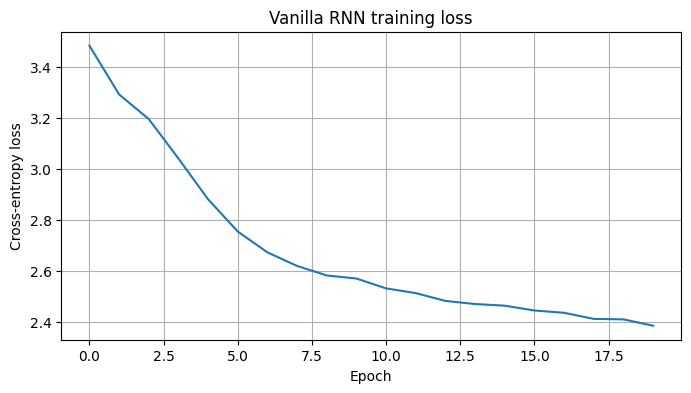

In [33]:
# Your plot code here
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.title('Vanilla RNN training loss')
plt.grid(True)
plt.show()

In [34]:
def generate_sample(char_rnn, seed_phrase=' Hello', max_length=MAX_LENGTH, temperature=1.0):
    '''
    ### Disclaimer: this is an example function for text generation.
    ### You can either adapt it in your code or create your own function

    The function generates text given a phrase of length at least SEQ_LENGTH.
    :param seed_phrase: prefix characters. The RNN is asked to continue the phrase
    :param max_length: maximum output length, including seed_phrase
    :param temperature: coefficient for sampling.  higher temperature produces more chaotic outputs,
        smaller temperature converges to the single most likely output.

    Be careful with the model output. This model waits logits (not probabilities/log-probabilities)
    of the next symbol.
    '''

    x_sequence = [token_to_id[token] for token in seed_phrase]
    x_sequence = torch.tensor([[x_sequence]], dtype=torch.int64)
    hid_state = char_rnn.initial_state(batch_size=1)

    #feed the seed phrase, if any
    for i in range(len(seed_phrase) - 1):
        print(x_sequence[:, -1].shape, hid_state.shape)
        out, hid_state = char_rnn(x_sequence[:, i], hid_state)

    #start generating
    for _ in range(max_length - len(seed_phrase)):
        print(x_sequence.shape, x_sequence, hid_state.shape)
        out, hid_state = char_rnn(x_sequence[:, -1], hid_state)
        # Be really careful here with the model output
        p_next = F.softmax(out / temperature, dim=-1).data.numpy()[0]

        # sample next token and push it back into x_sequence
        print(p_next.shape, len(tokens))
        next_ix = np.random.choice(len(tokens), p=p_next)
        next_ix = torch.tensor([[next_ix]], dtype=torch.int64)
        print(x_sequence.shape, next_ix.shape)
        x_sequence = torch.cat([x_sequence, next_ix], dim=1)

    return ''.join([tokens[ix] for ix in x_sequence.data.numpy()[0]])

In [36]:
@torch.no_grad()
def generate_text(model, seed_phrase='мой дядя', max_length=MAX_LENGTH, temperature=1.0):
    model.eval()
    x = torch.tensor([[token_to_idx[ch] for ch in seed_phrase.lower()]], dtype=torch.long, device=device)
    generated = x[0].tolist()
    logits, state = model(x)

    for _ in range(max_length - len(seed_phrase)):
        p_next = F.softmax(logits[0, -1] / temperature, dim=-1).cpu().numpy().astype(np.float64)
        p_next /= p_next.sum()
        next_ix = np.random.choice(len(tokens), p=p_next)
        generated.append(next_ix)
        x = torch.tensor([[next_ix]], dtype=torch.long, device=device)
        logits, state = model(x, state)

    return ''.join(idx_to_token[ix] for ix in generated)

In [39]:
# An example of generated text.
print(generate_text(char_rnn, max_length=500, temperature=0.2))

мой дядя не поровой
в редет серона,
подаль о поредный гороваль о провот поровоной



xxx



xxxii

на порой постраваль о предаль о воленье волоней
вотоль на поредной предаль о поредаль оно в порода



xxv

на предала в рого провади,
в дере не стореньей веров,
и продет у страсталь ов порого вородной деленье порода предет.



xxv

на празамен веране ворода



xxxii

на праза воредной демный поредна поредной вороваль ветравали не города преветь в сераль в серана



xxxii

не провой порет вестой вер


### More poetic model

Let's use LSTM instead of vanilla RNN and compare the results.

Plot the loss function of the number of epochs. Does the final loss become better?

LSTM epoch 1/20, loss: 3.5980
LSTM epoch 2/20, loss: 3.3120
LSTM epoch 3/20, loss: 3.2508
LSTM epoch 4/20, loss: 3.1137
LSTM epoch 5/20, loss: 2.9408
LSTM epoch 6/20, loss: 2.7848
LSTM epoch 7/20, loss: 2.6811
LSTM epoch 8/20, loss: 2.6081
LSTM epoch 9/20, loss: 2.5632
LSTM epoch 10/20, loss: 2.5217
LSTM epoch 11/20, loss: 2.4837
LSTM epoch 12/20, loss: 2.4564
LSTM epoch 13/20, loss: 2.4398
LSTM epoch 14/20, loss: 2.4141
LSTM epoch 15/20, loss: 2.3918
LSTM epoch 16/20, loss: 2.3736
LSTM epoch 17/20, loss: 2.3559
LSTM epoch 18/20, loss: 2.3475
LSTM epoch 19/20, loss: 2.3329
LSTM epoch 20/20, loss: 2.3123


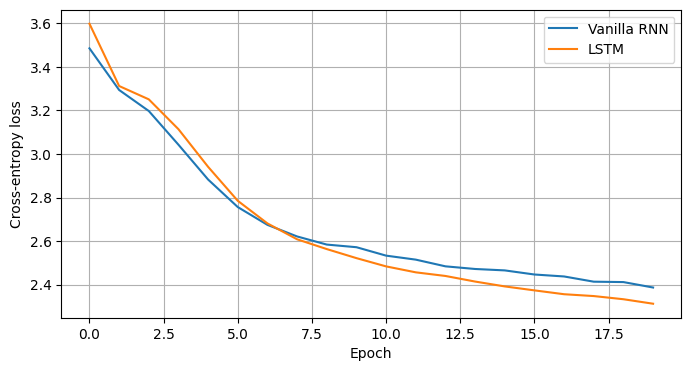

In [ ]:
# Your beautiful code
lstm_rnn = CharRNN(len(tokens), HIDDEN_SIZE, 'lstm').to(device)
lstm_optimizer = torch.optim.Adam(lstm_rnn.parameters(), lr=2e-3)
lstm_loss_history = []

for epoch in range(EPOCHS):
    lstm_rnn.train()
    total_loss, n_batches = 0.0, 0

    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        lstm_optimizer.zero_grad()
        logits, _ = lstm_rnn(x_batch)
        loss = criterion(logits.reshape(-1, len(tokens)), y_batch.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(lstm_rnn.parameters(), 1.0)
        lstm_optimizer.step()
        total_loss += loss.item()
        n_batches += 1
    epoch_loss = total_loss / max(n_batches, 1)
    lstm_loss_history.append(epoch_loss)
    print(f'LSTM epoch {epoch + 1}/{EPOCHS}, loss: {epoch_loss:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(loss_history, label='Vanilla RNN')
plt.plot(lstm_loss_history, label='LSTM')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.legend()
plt.grid(True)
plt.show()

Generate text using the trained net with different `temperature` parameter: `[0.1, 0.2, 0.5, 1.0, 2.0]`.

Evaluate the results visually, try to interpret them.

In [41]:
# Text generation with different temperature values here
for temperature in [0.1, 0.2, 0.5, 1.0, 2.0]:
    print('\n' + '=' * 20 + f' temperature={temperature} ' + '=' * 20)
    print(generate_text(lstm_rnn, seed_phrase='мой дядя', max_length=500, temperature=temperature))


==================== temperature=0.1 ====================
мой дядя не ворень,
полени предет он оно предет
и продом он оне не поровить,
и стора не поренит оной
и вол серень и предной поров
и стора не предет оно воров
и стора не поренит оной
и порен и в оне не поровой
и предет и провот и продой
и стора не предет оной стора



xxxiii

и в де на предне верени ворой
и стора на предет не домой
и порет оне верени вородной
и продет в серенный серадаль,
и в стора не воренный серать,
на волен о страна серенит,
и таль о провет поредной стора
не вол стора не предн

==================== temperature=0.2 ====================
мой дядя страна,
и сторе стерен воредной дали



xxxii

и на предной сворит вереть оне

в о на сторань он оно вестовой
и просталь о престеть он огой
и стора не предет и дора



xxxvii

и в столи не верен о провой,
не волен о бредный серена
и ворет онов и не серена



xxxiii

на стралить о брадала сладаль обора



xxxii

оне вол стора сторой серот
и ворет породни волоста,
и в лед

### Saving and loading models

Save the model to the disk, then load it and generate text. Examples are available [here](https://pytorch.org/tutorials/beginner/saving_loading_models.html]).

In [ ]:
# Saving and loading code here
checkpoint = {
    'model_state_dict': lstm_rnn.state_dict(),
    'vocab': tokens,
    'hidden_size': HIDDEN_SIZE,
    'cell_type': 'lstm'
}
torch.save(checkpoint, 'char_lstm.pth')

# Load the saved model
loaded_checkpoint = torch.load('char_lstm.pth', map_location=device, weights_only=False)
loaded_model = CharRNN(len(loaded_checkpoint['vocab']), loaded_checkpoint['hidden_size'], loaded_checkpoint['cell_type']).to(device)
loaded_model.load_state_dict(loaded_checkpoint['model_state_dict'])
loaded_model.eval()

print(generate_text(loaded_model, seed_phrase='мой дядя', max_length=500, temperature=0.8))

мой дядять, кая мера посра,
ю го еть в ятлобонитя стет;
и дабы и блыэтовирогда
и вась чиланье вонитне таменим, ведчей, содума, кот сае,
поробупот дво нем престольскам,
на ед срими рожнею посов…
но раствит метник я шедакильнествисть,
влах супочей лек и на нае:
с пакталь закраято вобол ил замалей;
полад не примакой милюблась.



«xxviii

и куженье молох тортужстьной наба
мо вие не моло денадвирне
согонов я престиль, – стор нужен новетмуми,
и стран сеским горог и ни чторам,
дальца прерат вим узным 


### References
1. <a href='http://karpathy.github.io/2015/05/21/rnn-effectiveness/'> Andrew Karpathy blog post about RNN. </a>
There are several examples of genration: Shakespeare texts, Latex formulas, Linux Sourse Code and children names.
2. <a href='https://github.com/karpathy/char-rnn'> Repo with char-rnn code </a>
3. Cool repo with PyTorch examples: [link](https://github.com/spro/practical-pytorch`)